In [ ]:
import torch, torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using', device)

# --- Load MNIST (28x28 greyscale digits, 10 classes) ---
train_full = datasets.MNIST('data', train=True,  download=True)
test_full  = datasets.MNIST('data', train=False, download=True)

# Flatten each 28x28 image into a 784-long vector and normalise pixels
def prep(ds):
    X = ds.data.float().div(255).view(-1, 784)
    X = (X - 0.1307) / 0.3081          # standard MNIST mean / std
    return X, ds.targets.long()

X_all, y_all = prep(train_full)
X_test, y_test = prep(test_full)       # official 10,000 test images = SEALED test set

# Three-way split: train / validation / test
# Train is deliberately SMALL so overfitting (and therefore dropout/epochs effects) is visible
N_TRAIN = 3000
g = torch.Generator().manual_seed(42)
perm = torch.randperm(len(X_all), generator=g)
tr_idx, val_idx = perm[:N_TRAIN], perm[50000:]          # 3,000 train, 10,000 validation

Xtr,  ytr  = X_all[tr_idx].to(device),  y_all[tr_idx].to(device)
Xval, yval = X_all[val_idx].to(device), y_all[val_idx].to(device)

print(f"Train: {len(ytr)}  Val: {len(yval)}  Test: {len(y_test)} (sealed)")

Using cpu
Train: 3000  Val: 10000  Test: 10000 (sealed)


In [ ]:
# Reusable function: builds + trains a model with the given hyperparameters,
# then returns its accuracy on the VALIDATION set
def train_eval(lr=1e-3, batch=64, dropout=0.3, optimizer_name='AdamW', epochs=30,
               seed=42, history=False):
    torch.manual_seed(seed)   # fix the random start so ONLY the hyperparameter changes between runs
    model = nn.Sequential(
        nn.Linear(784, 512), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(512, 512), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(512, 10),
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    # Pick the optimiser by name so we can vary it later
    opts = {
        'SGD':     torch.optim.SGD(model.parameters(), lr=lr),
        'RMSprop': torch.optim.RMSprop(model.parameters(), lr=lr),
        'Adam':    torch.optim.Adam(model.parameters(), lr=lr),
        'AdamW':   torch.optim.AdamW(model.parameters(), lr=lr),
    }
    optimizer = opts[optimizer_name]

    def accuracy(X, y):
        model.eval()
        with torch.no_grad():
            out = model(X)
        model.train()
        return (out.argmax(1) == y).float().mean().item(), loss_fn(out, y).item()

    hist = {'train_acc': [], 'val_acc': [], 'train_loss': [], 'val_loss': []}
    n = Xtr.shape[0]
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n, device=device)      # shuffle each epoch
        for i in range(0, n, batch):                 # one batch at a time
            idx = perm[i:i+batch]
            optimizer.zero_grad()
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            loss.backward()
            optimizer.step()
        if history:                                  # record curves every epoch (used for the epochs graph)
            ta, tl = accuracy(Xtr, ytr); va, vl = accuracy(Xval, yval)
            hist['train_acc'].append(ta); hist['val_acc'].append(va)
            hist['train_loss'].append(tl); hist['val_loss'].append(vl)

    if history:
        return hist
    return accuracy(Xval, yval)[0]


# --- Helper: run each value with 3 different seeds, return mean and std ---
SEEDS = [0, 1, 2]
results = {}

def sweep(name, values, **fixed):
    means, stds = [], []
    for v in values:
        accs = [train_eval(**{name: v}, seed=s, **fixed) for s in SEEDS]
        means.append(np.mean(accs)); stds.append(np.std(accs))
        print(f"{name}={v}: {np.mean(accs):.4f} ± {np.std(accs):.4f}")
    results[name] = (values, np.array(means), np.array(stds))
    return np.array(means), np.array(stds)

# Graph 1 - Learning Rate

lr=1e-05: 0.8728 ± 0.0007
lr=3e-05: 0.9021 ± 0.0005
lr=0.0001: 0.9268 ± 0.0006
lr=0.0003: 0.9358 ± 0.0010
lr=0.001: 0.9398 ± 0.0016
lr=0.003: 0.9303 ± 0.0025
lr=0.01: 0.8941 ± 0.0031
lr=0.03: 0.3291 ± 0.1051
lr=0.1: 0.1035 ± 0.0070


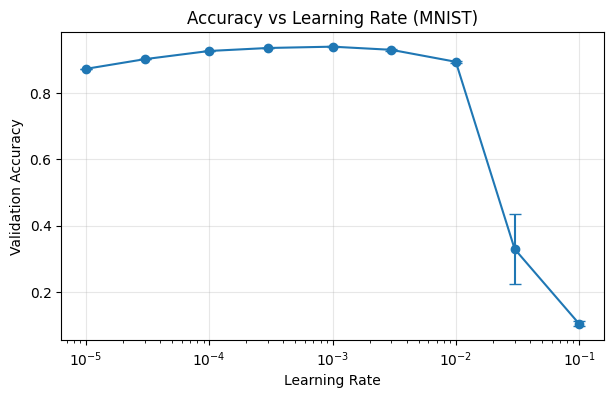

In [ ]:
lrs = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
m, s = sweep('lr', lrs)

plt.figure(figsize=(7,4))
plt.errorbar(lrs, m, yerr=s, marker='o', capsize=4)   # dot = mean of 3 seeds, bar = ± std
plt.xscale('log')                                      # log scale because values span 1e-5 to 1e-1
plt.xlabel('Learning Rate'); plt.ylabel('Validation Accuracy')
plt.title('Accuracy vs Learning Rate (MNIST)'); plt.grid(True, alpha=0.3)
plt.show()

#Graph 2 - Batch Size

batch=16: 0.9404 ± 0.0029
batch=32: 0.9372 ± 0.0018
batch=64: 0.9398 ± 0.0016
batch=128: 0.9356 ± 0.0013
batch=256: 0.9356 ± 0.0007
batch=512: 0.9333 ± 0.0018
batch=1024: 0.9304 ± 0.0013


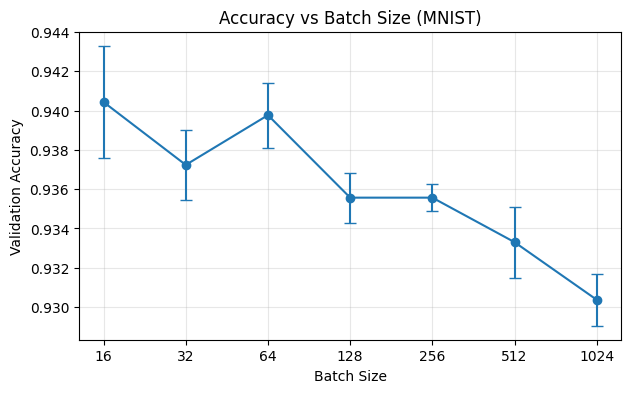

In [ ]:
batches = [16, 32, 64, 128, 256, 512, 1024]
m, s = sweep('batch', batches)

plt.figure(figsize=(7,4))
plt.errorbar(batches, m, yerr=s, marker='o', capsize=4)
plt.xscale('log', base=2)                              # batch sizes double each step
plt.xticks(batches, batches)
plt.xlabel('Batch Size'); plt.ylabel('Validation Accuracy')
plt.title('Accuracy vs Batch Size (MNIST)'); plt.grid(True, alpha=0.3)
plt.show()

# Graph 3 - Dropout

dropout=0.0: 0.9391 ± 0.0034
dropout=0.1: 0.9406 ± 0.0021
dropout=0.2: 0.9299 ± 0.0058
dropout=0.3: 0.9398 ± 0.0016
dropout=0.4: 0.9373 ± 0.0027
dropout=0.5: 0.9379 ± 0.0023
dropout=0.6: 0.9380 ± 0.0027
dropout=0.7: 0.9356 ± 0.0016
dropout=0.8: 0.9260 ± 0.0013


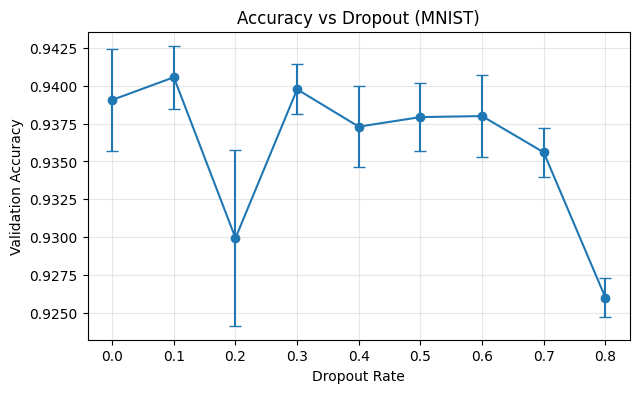

In [ ]:
drops = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
m, s = sweep('dropout', drops)

plt.figure(figsize=(7,4))
plt.errorbar(drops, m, yerr=s, marker='o', capsize=4)
plt.xlabel('Dropout Rate'); plt.ylabel('Validation Accuracy')
plt.title('Accuracy vs Dropout (MNIST)'); plt.grid(True, alpha=0.3)
plt.show()

#Graph 4 - Optimiser

optimizer_name=SGD: 0.7339 ± 0.0117
optimizer_name=RMSprop: 0.9361 ± 0.0086
optimizer_name=Adam: 0.9314 ± 0.0062
optimizer_name=AdamW: 0.9398 ± 0.0016


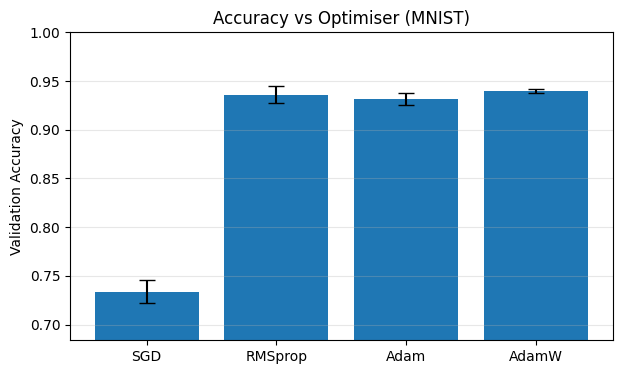

In [ ]:
opts = ['SGD', 'RMSprop', 'Adam', 'AdamW']
m, s = sweep('optimizer_name', opts)

plt.figure(figsize=(7,4))
plt.bar(opts, m, yerr=s, capsize=6)
plt.ylim(max(0, m.min() - 0.05), 1.0)
plt.ylabel('Validation Accuracy'); plt.title('Accuracy vs Optimiser (MNIST)')
plt.grid(True, axis='y', alpha=0.3)
plt.show()

#Graph 5 - Epochs

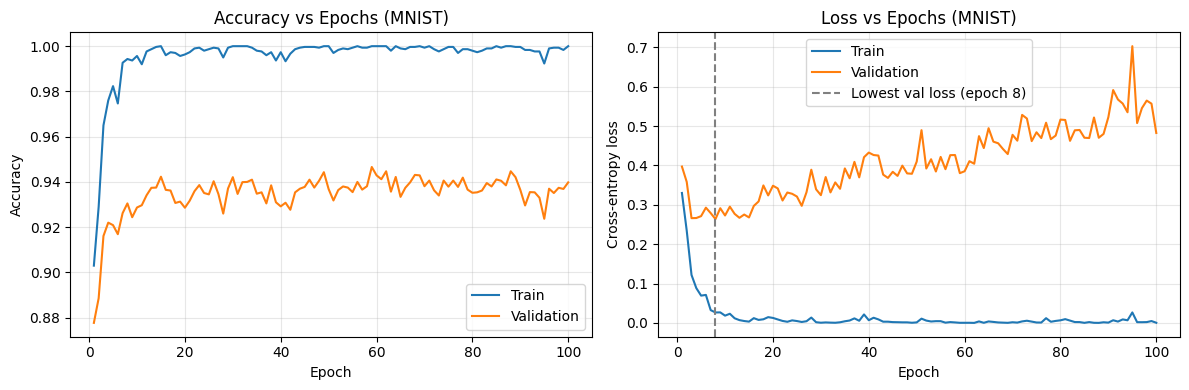

epochs=5: train=0.9823  val=0.9209  val_loss=0.2713
epochs=10: train=0.9957  val=0.9287  val_loss=0.2729
epochs=20: train=0.9963  val=0.9286  val_loss=0.3485
epochs=30: train=1.0000  val=0.9421  val_loss=0.3245
epochs=50: train=1.0000  val=0.9368  val_loss=0.4098
epochs=75: train=0.9997  val=0.9379  val_loss=0.4842
epochs=100: train=1.0000  val=0.9398  val_loss=0.4825


In [ ]:
hist = train_eval(epochs=100, history=True, seed=0)
ep = range(1, 101)

fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].plot(ep, hist['train_acc'], label='Train')
ax[0].plot(ep, hist['val_acc'],   label='Validation')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Accuracy'); ax[0].set_title('Accuracy vs Epochs (MNIST)')
ax[0].legend(); ax[0].grid(True, alpha=0.3)

ax[1].plot(ep, hist['train_loss'], label='Train')
ax[1].plot(ep, hist['val_loss'],   label='Validation')
best = int(np.argmin(hist['val_loss'])) + 1
ax[1].axvline(best, ls='--', c='grey', label=f'Lowest val loss (epoch {best})')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Cross-entropy loss'); ax[1].set_title('Loss vs Epochs (MNIST)')
ax[1].legend(); ax[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

for e in [5, 10, 20, 30, 50, 75, 100]:
    print(f"epochs={e}: train={hist['train_acc'][e-1]:.4f}  val={hist['val_acc'][e-1]:.4f}  val_loss={hist['val_loss'][e-1]:.4f}")

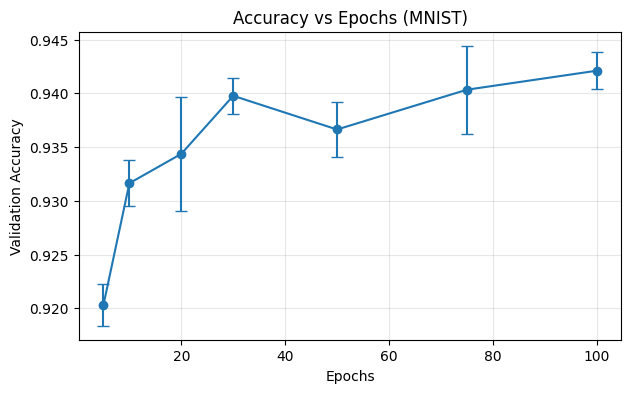

epochs=5: 0.9203 ± 0.0019
epochs=10: 0.9316 ± 0.0022
epochs=20: 0.9344 ± 0.0053
epochs=30: 0.9398 ± 0.0016
epochs=50: 0.9366 ± 0.0026
epochs=75: 0.9403 ± 0.0041
epochs=100: 0.9421 ± 0.0017


In [ ]:
# Train once per seed for 100 epochs, recording validation accuracy after every epoch
hists = [train_eval(epochs=100, history=True, seed=s) for s in SEEDS]
val = np.array([h['val_acc'] for h in hists])          # shape: (3 seeds, 100 epochs)

epoch_grid = [5, 10, 20, 30, 50, 75, 100]              # same points as the Kolam graph
m = val.mean(0)[[e-1 for e in epoch_grid]]             # mean over seeds at each point
s = val.std(0)[[e-1 for e in epoch_grid]]              # spread over seeds

plt.figure(figsize=(7,4))
plt.errorbar(epoch_grid, m, yerr=s, marker='o', capsize=4)
plt.xlabel('Epochs'); plt.ylabel('Validation Accuracy')
plt.title('Accuracy vs Epochs (MNIST)'); plt.grid(True, alpha=0.3)
plt.show()

for e, a, sd in zip(epoch_grid, m, s): print(f"epochs={e}: {a:.4f} ± {sd:.4f}")

hist = hists[0]; ep = range(1, 101)   # keeps the combined-figure cell working